In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as cm
import seaborn as sns
import plotnine as p9

#Style Configuration
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": "Helvetica",
    "font.size": 8,
    "axes.labelsize": 8.5,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 7.5,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 300
})

# **Figure 3**

In [2]:
#General maps
STRAIN_ORDER = ["P octanoia", "P pyruvativorans", "C sporogenes"]

STRAIN_DISPLAY = {"P octanoia": "P. octanoia",
                  "P pyruvativorans": "P. pyruvativorans",
                  "C sporogenes": "C. sporogenes"}

MEDIA_ORDER = ["10% mDSM104 + casAA",
               "10% mDSM104 + casAA + lactate",
               "10% mDSM104 + casAA + ethanol"]

MEDIA_DISPLAY = {"10% mDSM104 + casAA": "Base (+casAA)", 
                 "10% mDSM104 + casAA + lactate": "+ Lactate", 
                 "10% mDSM104 + casAA + ethanol": "+ Ethanol"}

CARBOXYLATES = ["Acetate", "Propanoate", "Iso-butanoate", "Butanoate", "Iso-pentanoate", 
                "Pentanoate", "Iso-hexanoate", "Hexanoate", "Heptanoate", "Octanoate"]

NITROGENOUS = ["Ammonium", "5-Aminovalerate"]

MEDIA_COLORS = {"10% mDSM104 + casAA": "#595959",  # Slate Gray
                "10% mDSM104 + casAA + lactate": "#1B6EC2",  # Royal Blue
                "10% mDSM104 + casAA + ethanol": "#009E73",  # Teal Green
               }

PRODUCT_COLORS = {"Acetate":        "#8DC9BF",
                  "Propanoate":     "#7B9AB8",
                  "Iso-butanoate":  "#D8BEA4",
                  "Butanoate":      "#3AAFA9",
                  "Iso-pentanoate": "#B89070",
                  "Pentanoate":     "#476896",
                  "Iso-hexanoate":  "#7D5638",
                  "Hexanoate":      "#2B7A78",
                  "Heptanoate":     "#1B365D",
                  "Octanoate":      "#17252A",
                  "Ammonium": "gray",
                  "5-Aminovalerate": "#D55E00"}

### Panel A - Growth curves across three formulations of 10% m104 with 20 g L-1 casamino acids with either added lactate or ethanol

In [3]:
#OD600 data
df_OD600 = pd.read_excel('Figure3.xlsx', sheet_name='OD600', engine ='openpyxl')
df_OD600.head()

,Strain,Media,Time (h),Replicate A,Replicate B,Replicate C
0,P octanoia,10% mDSM104 + casAA,0.0,0.007,0.013,0.014
1,P octanoia,10% mDSM104 + casAA,18.0,0.034,0.032,0.024
2,P octanoia,10% mDSM104 + casAA,22.0,0.035,0.035,0.034
3,P octanoia,10% mDSM104 + casAA,25.0,0.042,0.042,0.038
4,P octanoia,10% mDSM104 + casAA,42.0,0.152,0.123,0.113


In [4]:
# Change the data to long format
rep_cols = [
    c
    for c in ["Replicate A", "Replicate B", "Replicate C"]
    if c in df_OD600.columns
]
id_vars = [
    c
    for c in ["Strain", "Media", "Time (h)"]
    if c in df_OD600.columns
]

OD_long = df_OD600.melt(id_vars=id_vars, value_vars=rep_cols, var_name="Replicate", 
                        value_name="OD600").dropna(subset=["OD600"])

OD_long.head()

,Strain,Media,Time (h),Replicate,OD600
0,P octanoia,10% mDSM104 + casAA,0.0,Replicate A,0.007
1,P octanoia,10% mDSM104 + casAA,18.0,Replicate A,0.034
2,P octanoia,10% mDSM104 + casAA,22.0,Replicate A,0.035
3,P octanoia,10% mDSM104 + casAA,25.0,Replicate A,0.042
4,P octanoia,10% mDSM104 + casAA,42.0,Replicate A,0.152


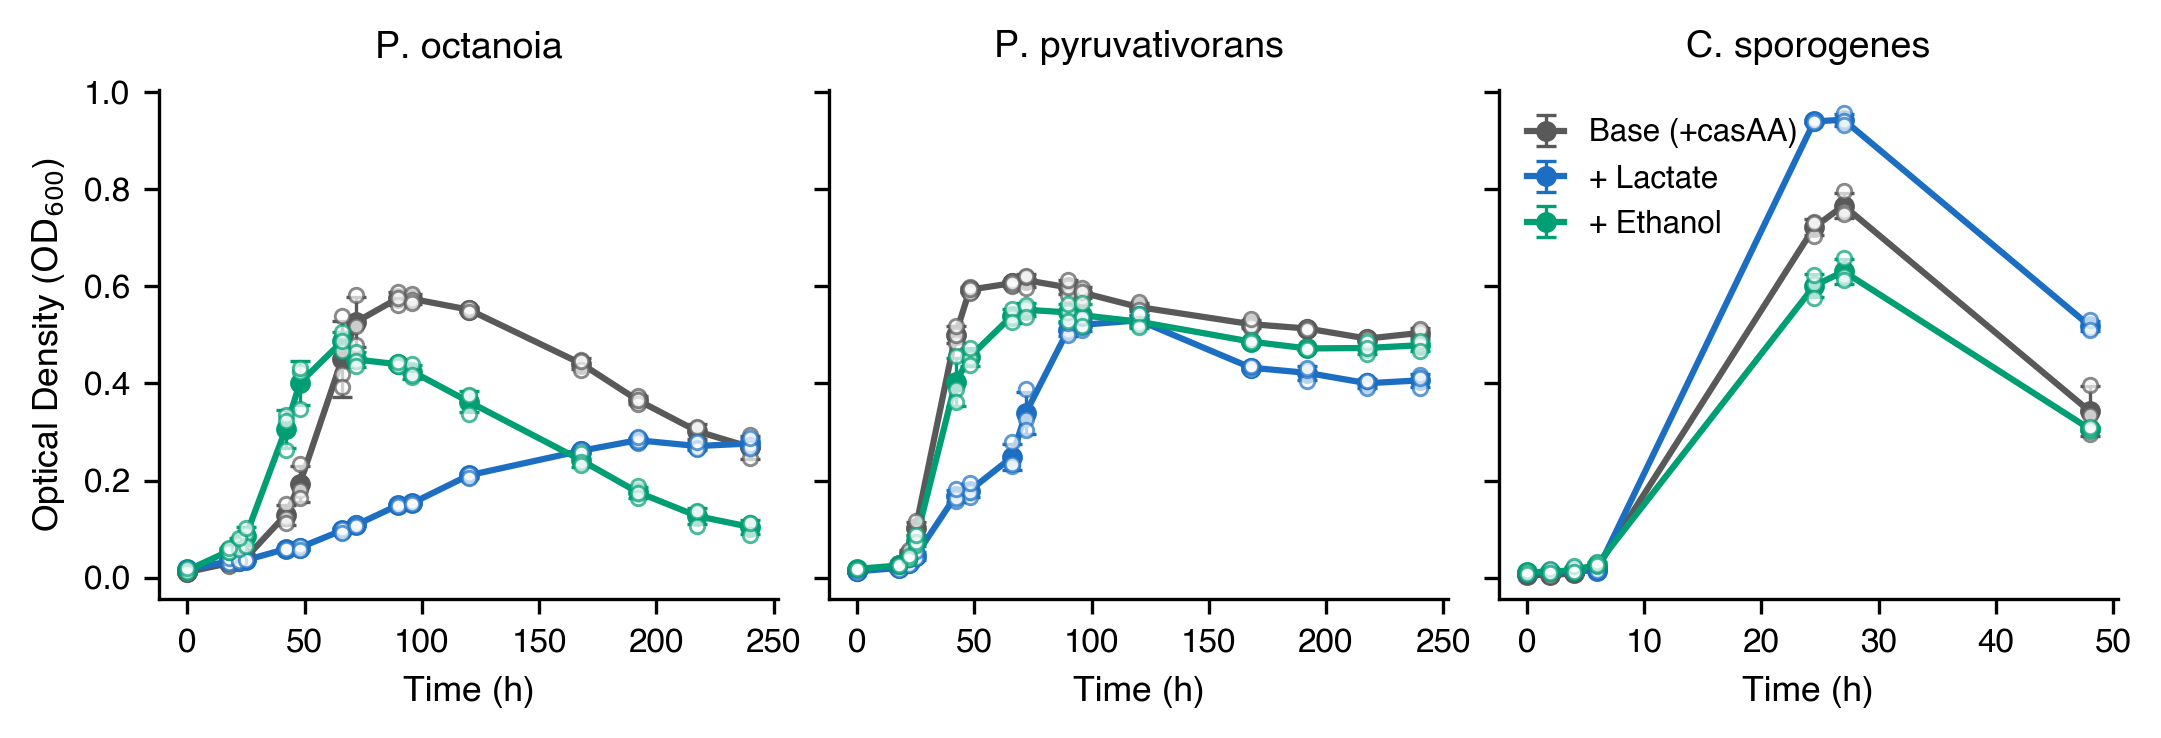

In [5]:
#Plot
fig, axes = plt.subplots(nrows=1, ncols=len(STRAIN_ORDER), figsize=(7.2, 2.5), sharey=True)

for idx, strain in enumerate(STRAIN_ORDER):
    ax = axes[idx]
    #axis panel styling
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.tick_params(axis="both", which="both", colors="black")

    for media in MEDIA_ORDER:
        color = MEDIA_COLORS.get(media, "#333333")
        media_label = MEDIA_DISPLAY.get(media, media)

        sub = OD_long[(OD_long["Strain"] == strain) & (OD_long["Media"] == media)]
        if sub.empty:
            continue

        grouped = (sub.groupby("Time (h)")["OD600"].agg(["mean", "std"]).dropna(subset=["mean"]))
        time = grouped.index.values
        avg = grouped["mean"].values
        stdev = grouped["std"].fillna(0).values

        #Mean line plot with standard deviation as error bars
        ax.errorbar(time, avg, yerr=stdev, fmt="o-", color=color, linewidth=1.5, markersize=4, 
                    capsize=2.5, capthick=0.8, elinewidth=0.8, label=media_label, zorder=3)

        #Replicate data as scatter points overlay
        ax.scatter(sub["Time (h)"], sub["OD600"], s=12, facecolors="white", 
                   edgecolors=color, alpha=0.7, linewidths=0.7, zorder=4)

    ax.set_title(STRAIN_DISPLAY.get(strain, strain), fontstyle="italic", pad=8)
    ax.set_xlabel("Time (h)")

    if idx == 0:
        ax.set_ylabel("Optical Density ($\mathrm{OD}_{600}$)")
    if idx == len(STRAIN_ORDER) - 1:
        ax.legend(frameon=False, loc="upper left", handlelength=1.2)
        
plt.tight_layout()
#save and export
plt.savefig("Figure3A_OD600.svg", bbox_inches="tight", transparent=True)
plt.savefig("Figure3A_OD600.png", bbox_inches="tight")
plt.show()

### Panel B , C - Deamination, 5-aminovalerate, and  Carboxylate formation at experimental endpoints

In [6]:
#products data file
df_prod = pd.read_excel('Figure3.xlsx', sheet_name='Products', engine = 'openpyxl')
df_prod.head()

,Strain,Media,Replicate,Acetate,Propanoate,Iso-butanoate,Butanoate,Iso-pentanoate,Pentanoate,Iso-hexanoate,Hexanoate,Heptanoate,Octanoate,Ammonium,5-Aminovalerate
0,P octanoia,10% mDSM104 + casAA,A,2.447,0.0,1.462,0.365,2.750,0.059,0.226,1.055,0.784,1.917,34.606,16.589
1,P octanoia,10% mDSM104 + casAA,B,2.574,0.0,1.517,0.408,2.716,0.063,0.271,1.010,0.805,1.938,34.596,15.765
2,P octanoia,10% mDSM104 + casAA,C,2.528,0.0,1.493,0.404,2.764,0.069,0.252,1.155,0.733,2.090,34.405,15.383
3,P octanoia,10% mDSM104 + casAA + lactate,A,9.103,0.0,0.496,0.930,0.170,0.000,0.073,2.720,0.076,3.806,16.003,12.634
4,P octanoia,10% mDSM104 + casAA + lactate,B,9.285,0.0,0.472,0.929,0.175,0.000,0.062,2.682,0.077,3.931,16.496,14.634


In [7]:
# Change the data to long format
metadata_cols = ["Strain", "Media", "Replicate"]
product_cols = [c for c in df_prod.columns if c not in metadata_cols]

df_long = df_prod.melt(id_vars=metadata_cols, value_vars=product_cols, 
                       var_name="Metabolite", value_name="Concentration")
df_long.head()

,Strain,Media,Replicate,Metabolite,Concentration
0,P octanoia,10% mDSM104 + casAA,A,Acetate,2.447
1,P octanoia,10% mDSM104 + casAA,B,Acetate,2.574
2,P octanoia,10% mDSM104 + casAA,C,Acetate,2.528
3,P octanoia,10% mDSM104 + casAA + lactate,A,Acetate,9.103
4,P octanoia,10% mDSM104 + casAA + lactate,B,Acetate,9.285


In [8]:
grouped = df_long.groupby(["Strain", "Media", "Metabolite"])["Concentration"].agg(["mean", "std"]).reset_index()

#### Panel B

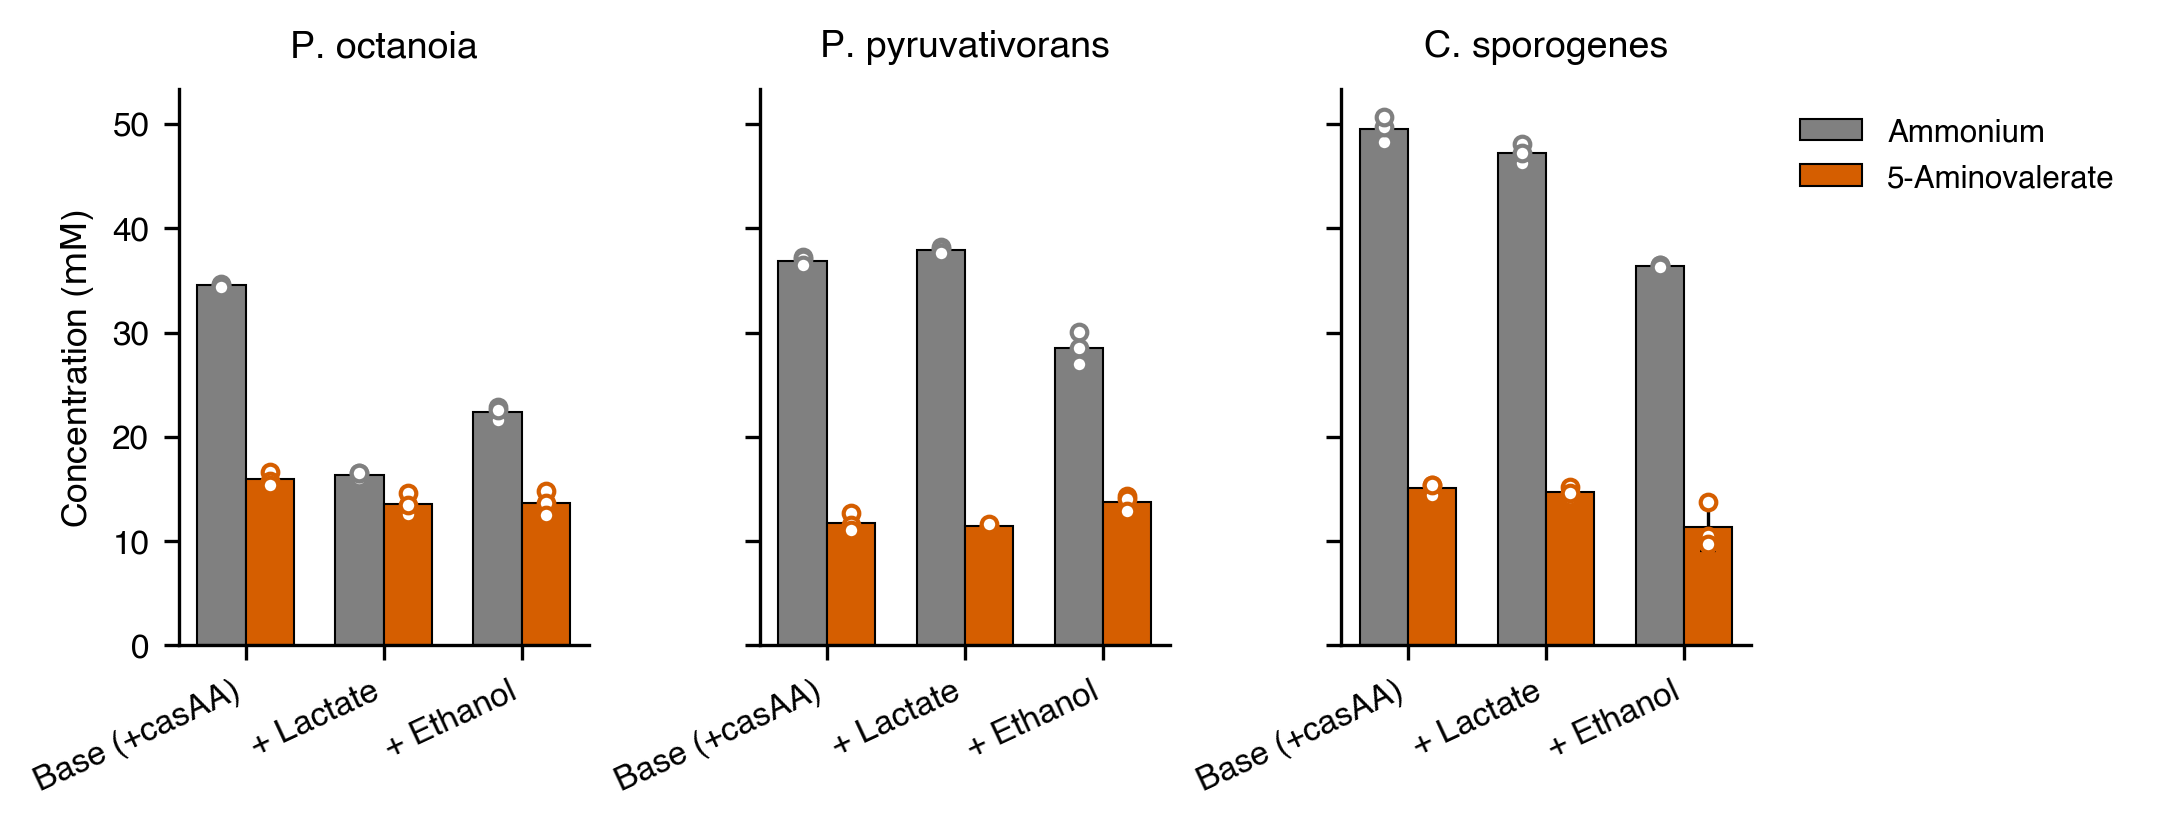

In [9]:
#Plot ammonium and 5-aminovalerate
fig, axes = plt.subplots(1, len(STRAIN_ORDER), figsize=(7.2, 2.8), sharey=True)
bar_width = 0.35

for idx, strain in enumerate(STRAIN_ORDER):
    ax = axes[idx]
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    strain_df = grouped[grouped["Strain"] == strain]
    strain_raw = df_long[df_long["Strain"] == strain]

    media = [m for m in MEDIA_ORDER if m in strain_df["Media"].unique()]
    x_pos = np.arange(len(media))

    for m_idx, metab in enumerate(NITROGENOUS):
        vals = []
        stds = []
        for m in media:
            sub = strain_df[(strain_df["Media"] == m) & (strain_df["Metabolite"] == metab)]
            vals.append(sub["mean"].values[0] if not sub.empty else 0.0)
            stds.append(sub["std"].values[0] if not sub.empty else 0.0)

        vals = np.array(vals)
        stds = np.array(stds)
        color = PRODUCT_COLORS.get(metab, "#CCCCCC")

        offset = (m_idx - 0.5) * bar_width
        x_bar_centers = x_pos + offset

        #grouped bars
        ax.bar(x_bar_centers, vals, width=bar_width, yerr=stds, capsize=2, error_kw={"linewidth": 0.8},
               label=metab if idx == 0 else "", color=color, edgecolor="black", linewidth=0.5, zorder=2)

        #scatter points for individual replicates
        for x_c, m in zip(x_bar_centers, media):
            raw_pts = strain_raw[(strain_raw["Media"] == m) & (strain_raw["Metabolite"] == metab)]["Concentration"].values
            ax.scatter([x_c] * len(raw_pts), raw_pts, facecolors="white", edgecolors=color,
                       linewidths=1.0, s=14, zorder=4)

    ax.set_title(STRAIN_DISPLAY.get(strain, strain), fontstyle="italic", pad=8)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([MEDIA_DISPLAY.get(m, m) for m in media], rotation=25, ha="right")

    if idx == 0:
        ax.set_ylabel("Concentration ($\mathrm{mM}$)")

handles = [plt.Rectangle((0, 0), 1, 1, color=PRODUCT_COLORS[m], ec="black", lw=0.5)
           for m in NITROGENOUS]
axes[-1].legend(handles, NITROGENOUS, bbox_to_anchor=(1.05, 1),
                loc="upper left", frameon=False)

plt.tight_layout()
plt.savefig("Figure3B.svg", bbox_inches="tight", transparent=True)
plt.savefig("Figure3B.png", bbox_inches="tight")
plt.show()

#### Panel C

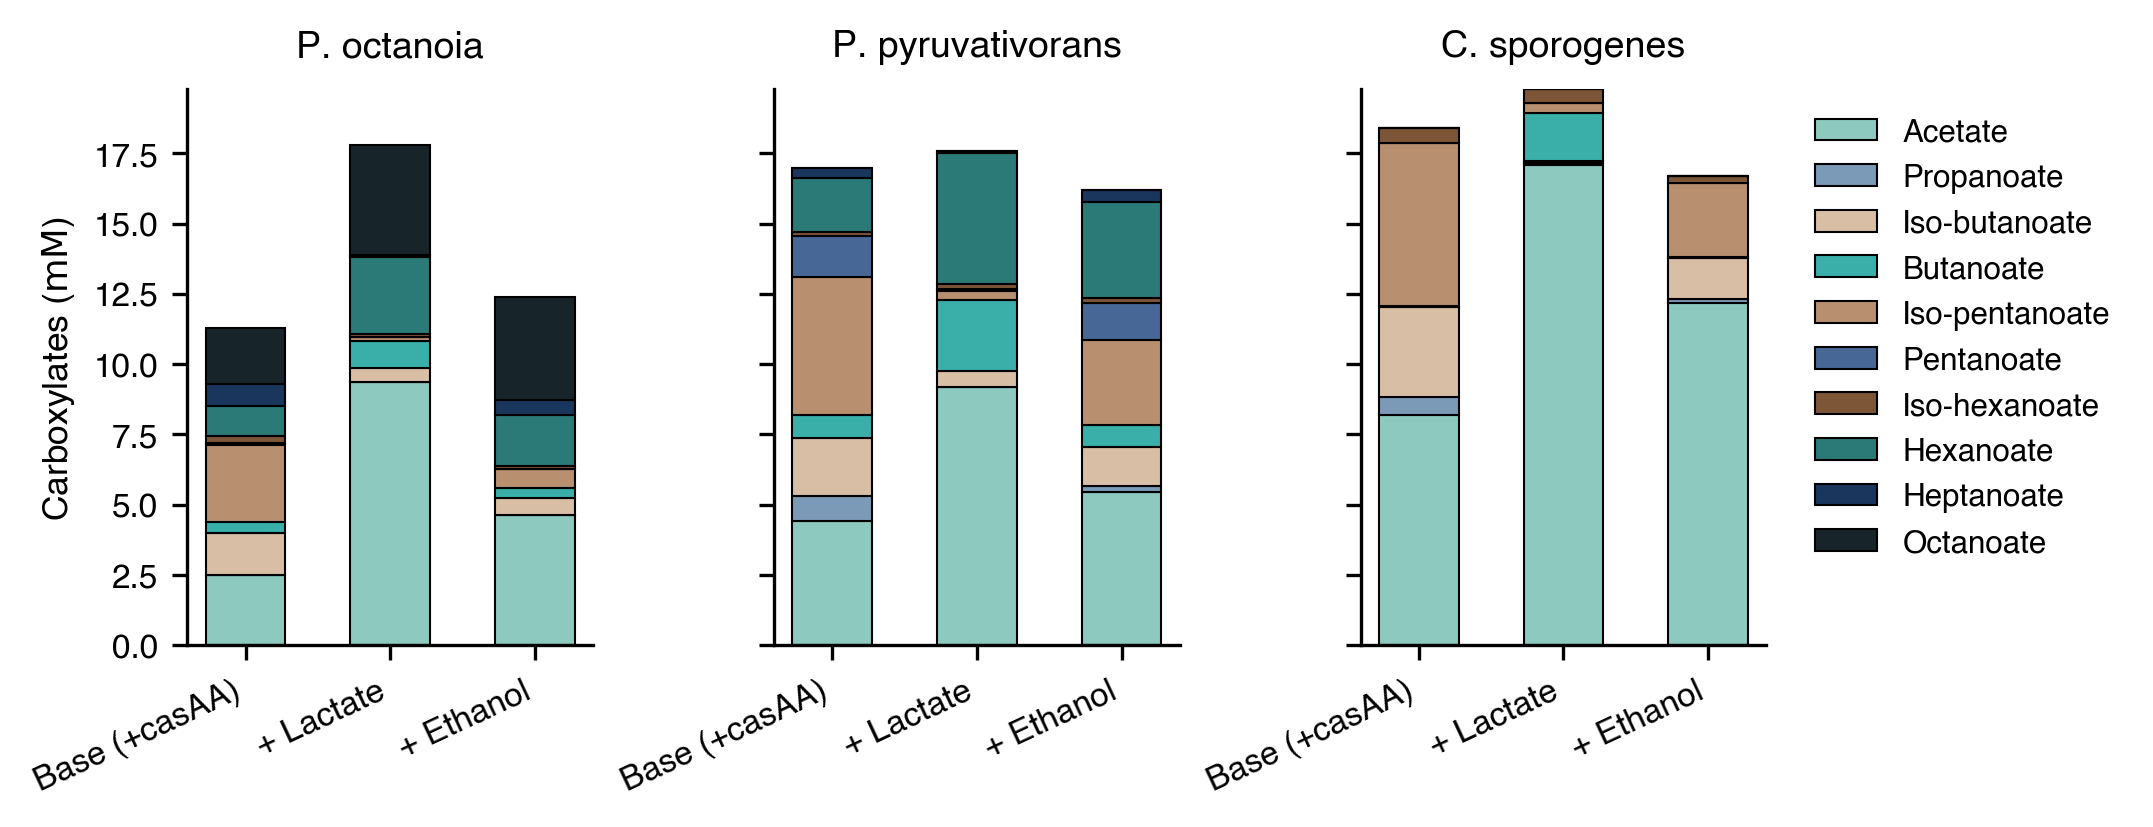

In [10]:
#Plot Carboxylates
fig, axes = plt.subplots(1, len(STRAIN_ORDER), figsize=(7.2, 2.8), sharey=True)

for idx, strain in enumerate(STRAIN_ORDER):
    ax = axes[idx]
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(0.8)
    ax.spines["bottom"].set_linewidth(0.8)

    strain_df = grouped[grouped["Strain"] == strain]
    media = [m for m in MEDIA_ORDER if m in strain_df["Media"].unique()]
    x_pos = np.arange(len(media))
    bottoms = np.zeros(len(media))

    for metab in CARBOXYLATES:
        vals = []
        for m in media:
            sub = strain_df[(strain_df["Media"] == m) & (strain_df["Metabolite"] == metab)]
            vals.append(sub["mean"].values[0] if not sub.empty else 0.0)

        vals = np.array(vals)
        color = PRODUCT_COLORS.get(metab, "#CCCCCC")

        ax.bar(x_pos, vals, bottom=bottoms, color=color, 
               edgecolor="black", linewidth=0.5, width=0.55)
        bottoms += vals

    ax.set_title(STRAIN_DISPLAY.get(strain, strain), fontstyle="italic", pad=8)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([MEDIA_DISPLAY.get(m, m) for m in media], rotation=25, ha="right")

    if idx == 0:
        ax.set_ylabel("Carboxylates ($\mathrm{mM}$)")

handles = [plt.Rectangle((0, 0), 1, 1, color=PRODUCT_COLORS[m], ec="black", lw=0.5)
           for m in CARBOXYLATES]
axes[-1].legend(handles, CARBOXYLATES, bbox_to_anchor=(1.05, 1),
                loc="upper left", frameon=False)

plt.tight_layout()
plt.savefig("Figure3C.svg", bbox_inches="tight")
plt.savefig("Figure3C.png", bbox_inches="tight")
plt.show()

### Panel D - Change in extracellular amino acid concentrations between experimental endpoint and initial conditions

In [11]:
#Data
aas = pd.read_excel("Figure3.xlsx",sheet_name="AAs_utilization",skiprows=1)
aas['Thr'] = aas['Thr_3d'] # using the fully derivatized form as proxy (i.e., 2TBDMS as opposed to 3TBDMS)
aas = aas.drop(columns=['Thr_2d', 'Thr_3d', 'Cys'])

In [12]:
# Average initial AA concentration across all blanks and generate a ranking for the y-axis
blank = aas[aas["STRAIN"] == "BLANK"].copy()

blank_long = blank.melt(id_vars=["MEDIA", "R", "STRAIN"], var_name="AminoAcid", value_name="InitialConc")

aa_rank = (blank_long.groupby("AminoAcid", as_index=False)
    .agg(mean_initial=("InitialConc", "mean"))
    .sort_values("mean_initial", ascending=False))

aa_order = aa_rank["AminoAcid"].tolist() # rank AAs
aa_noblanks = aas[aas["STRAIN"] != "BLANK"].copy() 

aa_long = aa_noblanks.melt(id_vars=["MEDIA", "R", "STRAIN"], var_name="AminoAcid", value_name="Utilization")

aa_long["Utilization"] = -aa_long["Utilization"]

aa_long["AminoAcid"] = pd.Categorical(aa_long["AminoAcid"], categories=aa_order, ordered=True)

In [13]:
morder = ["PY10+CAS", "PY10+CAS+LAC", "PY10+CAS+EtOH"]

In [14]:
aa_long["MEDIA"] = pd.Categorical(aa_long["MEDIA"], categories=morder, ordered=True)

aa_avg = (aa_long.groupby(["MEDIA", "STRAIN", "AminoAcid"], as_index=False, observed=True)   
    .agg(Utilization_mean=("Utilization", "mean")))

aa_avg["AminoAcid"] = pd.Categorical(aa_avg["AminoAcid"], categories=aa_order, ordered=True)

aa_avg["MED_STR"] = aa_avg["MEDIA"].astype(str) + "_" + aa_avg["STRAIN"].astype(str)

/Users/dk/miniforge3/envs/py311/lib/python3.11/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_point : Removed 13 rows containing missing values.


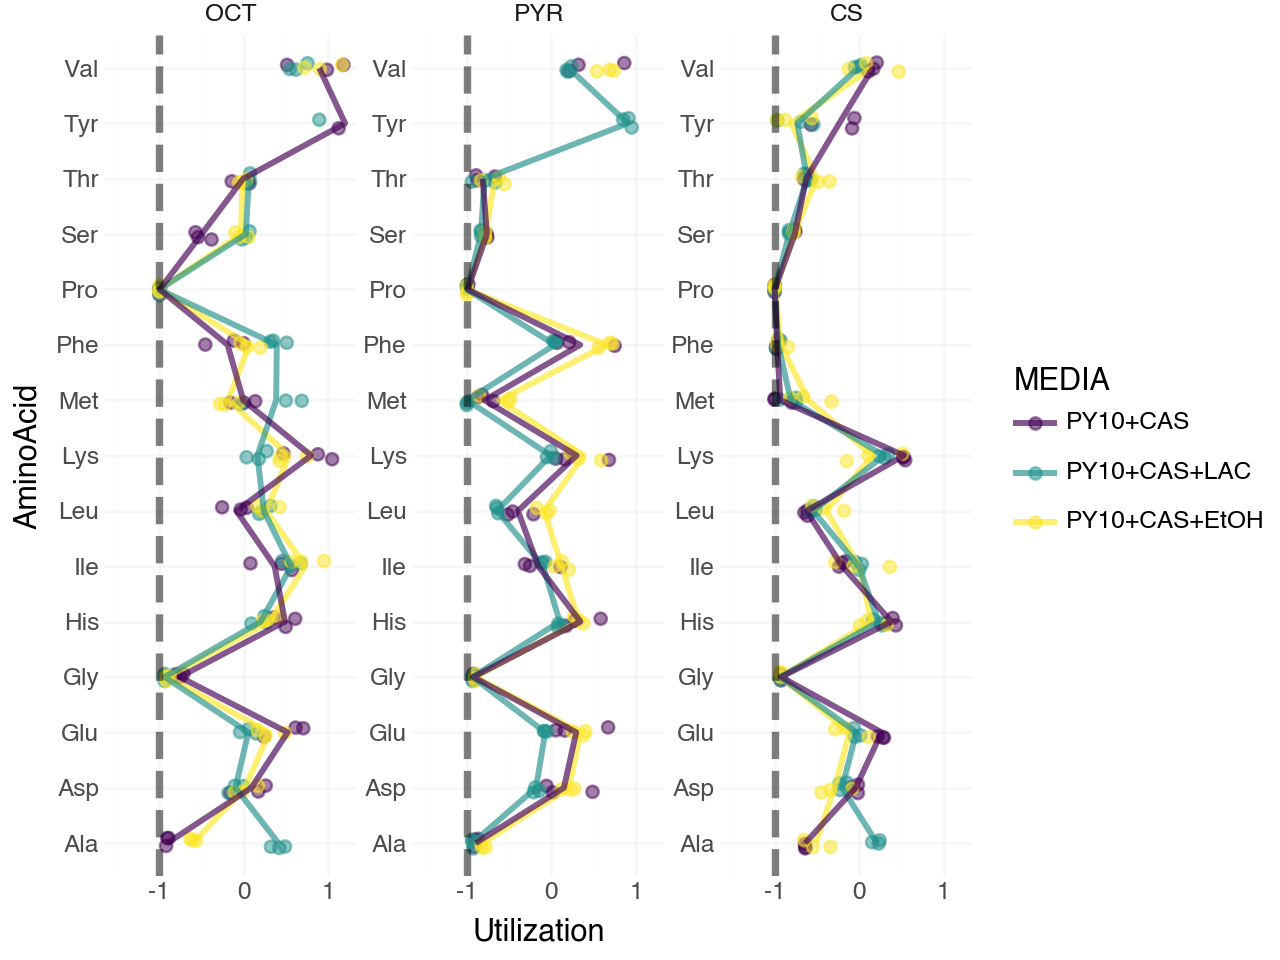

In [15]:
#Plot figure with alphabetical sorting
aa_order = sorted(set(aa_long["AminoAcid"]) | set(aa_avg["AminoAcid"]))

aa_long["AminoAcid"] = pd.Categorical(aa_long["AminoAcid"], categories=aa_order, ordered=True)
aa_avg["AminoAcid"]  = pd.Categorical(aa_avg["AminoAcid"],  categories=aa_order, ordered=True)

aa_avg = aa_avg.sort_values(["MED_STR", "AminoAcid"])

strain_order = ["OCT", "PYR", "CS"]

aa_long["STRAIN"] = pd.Categorical(aa_long["STRAIN"], categories=strain_order, ordered=True)
aa_avg["STRAIN"]  = pd.Categorical(aa_avg["STRAIN"],  categories=strain_order, ordered=True)

aa_util = (p9.ggplot(aa_long, p9.aes(x="Utilization", y="AminoAcid", colour="MEDIA", group="MEDIA"))
    + p9.geom_point(size=2, alpha=0.5, position=p9.position_jitter(height=0.1, width=0))
    + p9.geom_path(data=aa_avg,
                   mapping=p9.aes("Utilization_mean", "AminoAcid", group="MED_STR", colour="MEDIA"),
                   alpha=0.66, size=1.2)
    + p9.geom_vline(xintercept=-1, linetype="dashed", alpha=0.5, size=1.5)
    + p9.facet_wrap("~STRAIN", nrow=1, scales="free_y")
    + p9.scale_x_continuous(limits=(-1.5, 1.2))
    + p9.theme_minimal()
)
aa_util